# Gelation Detection — Isothermal Rheology Data
**Project:** Wavelet-Based Time–Frequency Analysis of Evolving Fluids (Haemograph)

**Sheet used:** `Table 3A_6_ raw data` — isothermal measurements at 85°C, 90°C, 95°C for 6 adhesive systems.

**Gelation criteria applied (logical conditions):**
1. **G' > G''** (tan δ < 1) — crossover marks the gel point
2. **Sustained crossover** — G' > G'' must hold for ≥3 consecutive rows (avoids noise spikes)
3. **Rising G'** — storage modulus must be increasing over a rolling window (solid network forming)
4. **tan δ trend** — tan δ must be decreasing toward and below 1


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from openpyxl import load_workbook
import warnings
warnings.filterwarnings('ignore')

print('Libraries loaded.')

Libraries loaded.


## 1. Load Data from Excel
The sheet has a multi-header layout: each adhesive × temperature combination occupies a 6-column block.

In [2]:
FILE_PATH = 'one.xlsx'
SHEET_NAME = 'Table 3A_6_ raw data'

wb = load_workbook(FILE_PATH, read_only=True)
ws = wb[SHEET_NAME]
all_rows = list(ws.iter_rows(values_only=True))

# Row layout:
#   Row 0: adhesive names (at column start of each block)
#   Row 1: temperature labels
#   Row 2: column names (TIME, TEMPERATURE, STORAGE MODULUS, LOSS MODULUS, TAN DELTA, COMPLEX VISCOSITY)
#   Row 3: units
#   Row 4+: data

adhesive_row = all_rows[0]
temp_row     = all_rows[1]

# Discover all blocks: wherever a non-null adhesive name appears
blocks = []
current_adhesive = None
for col_idx, val in enumerate(adhesive_row):
    if val and val != 'ADHESIVE':
        current_adhesive = val
    if temp_row[col_idx] and str(temp_row[col_idx]).endswith('°C'):
        blocks.append({
            'adhesive': current_adhesive,
            'temp': temp_row[col_idx],
            'col_start': col_idx
        })

print(f'Found {len(blocks)} adhesive × temperature blocks:')
for b in blocks:
    print(f"  {b['adhesive']} @ {b['temp']}  (starting col {b['col_start']})")

Found 18 adhesive × temperature blocks:
  Fru-BHT @ 85°C  (starting col 1)
  Fru-BHT @ 90°C  (starting col 7)
  Fru-BHT @ 95°C  (starting col 13)
  Fru-HMF(5%)-BHT @ 85°C  (starting col 19)
  Fru-HMF(5%)-BHT @ 90°C  (starting col 25)
  Fru-HMF(5%)-BHT @ 95°C  (starting col 31)
  Fru-HMF(50%)-BHT @ 85°C  (starting col 37)
  Fru-HMF(50%)-BHT @ 90°C  (starting col 43)
  Fru-HMF(50%)-BHT @ 95°C  (starting col 49)
  Fru-HMDA @ 85°C  (starting col 55)
  Fru-HMDA @ 90°C  (starting col 61)
  Fru-HMDA @ 95°C  (starting col 67)
  Fru-HMF(5%)-HMDA @ 85°C  (starting col 73)
  Fru-HMF(5%)-HMDA @ 90°C  (starting col 79)
  Fru-HMF(5%)-HMDA @ 95°C  (starting col 85)
  Fru-HMF(50%)-HMDA @ 85°C  (starting col 91)
  Fru-HMF(50%)-HMDA @ 90°C  (starting col 97)
  Fru-HMF(50%)-HMDA @ 95°C  (starting col 103)


In [3]:
def extract_block(all_rows, col_start, data_start_row=4):
    """Extract one 6-column block as a clean DataFrame."""
    cols = ['time_s', 'temp_C', 'G_prime_Pa', 'G_dprime_Pa', 'tan_delta', 'eta_star_mPas']
    records = []
    for row in all_rows[data_start_row:]:
        if col_start + 5 >= len(row):
            continue
        segment = row[col_start: col_start + 6]
        # Skip rows where TIME is missing
        if segment[0] is None:
            continue
        try:
            records.append([float(x) if x is not None else np.nan for x in segment])
        except (TypeError, ValueError):
            continue
    df = pd.DataFrame(records, columns=cols)
    df = df.dropna(subset=['time_s', 'G_prime_Pa', 'G_dprime_Pa'])
    df = df.reset_index(drop=True)
    return df

# Build a dict of all DataFrames
datasets = {}
for b in blocks:
    key = f"{b['adhesive']} @ {b['temp']}"
    df = extract_block(all_rows, b['col_start'])
    datasets[key] = df
    print(f'{key}: {len(df)} rows')

Fru-BHT @ 85°C: 52 rows
Fru-BHT @ 90°C: 29 rows
Fru-BHT @ 95°C: 68 rows
Fru-HMF(5%)-BHT @ 85°C: 31 rows
Fru-HMF(5%)-BHT @ 90°C: 22 rows
Fru-HMF(5%)-BHT @ 95°C: 23 rows
Fru-HMF(50%)-BHT @ 85°C: 41 rows
Fru-HMF(50%)-BHT @ 90°C: 33 rows
Fru-HMF(50%)-BHT @ 95°C: 28 rows
Fru-HMDA @ 85°C: 95 rows
Fru-HMDA @ 90°C: 47 rows
Fru-HMDA @ 95°C: 60 rows
Fru-HMF(5%)-HMDA @ 85°C: 50 rows
Fru-HMF(5%)-HMDA @ 90°C: 50 rows
Fru-HMF(5%)-HMDA @ 95°C: 36 rows
Fru-HMF(50%)-HMDA @ 85°C: 37 rows
Fru-HMF(50%)-HMDA @ 90°C: 27 rows
Fru-HMF(50%)-HMDA @ 95°C: 29 rows


## 2. Gelation Detection Logic

We apply four logical conditions row-by-row, then combine them:

In [4]:
def detect_gelation(df, sustained_n=3, rolling_window=5):
    """
    Apply gelation criteria to a rheology DataFrame.

    Conditions:
      C1: G' > G''                          (elastic dominates viscous)
      C2: tan_delta < 1                     (equivalent to C1, cross-check)
      C3: G' is increasing (rolling slope > 0)
      C4: Sustained C1 for >= sustained_n consecutive rows

    Returns the DataFrame with condition columns added,
    plus a summary dict.
    """
    df = df.copy()

    # --- Condition 1: G' > G'' ---
    df['C1_elastic_dominant'] = df['G_prime_Pa'] > df['G_dprime_Pa']

    # --- Condition 2: tan δ < 1 ---
    df['C2_tan_delta_lt1'] = df['tan_delta'] < 1.0

    # --- Condition 3: G' rising (rolling linear slope over window) ---
    def rolling_slope(series, w):
        slopes = [np.nan] * len(series)
        arr = series.values
        for i in range(w - 1, len(arr)):
            y = arr[i - w + 1: i + 1]
            if np.any(np.isnan(y)):
                continue
            x = np.arange(w, dtype=float)
            slope = np.polyfit(x, y, 1)[0]
            slopes[i] = slope
        return pd.Series(slopes, index=series.index)

    df['G_prime_slope'] = rolling_slope(df['G_prime_Pa'], rolling_window)
    df['C3_G_prime_rising'] = df['G_prime_slope'] > 0

    # --- Condition 4: Sustained C1 (consecutive rows where G' > G'') ---
    sustained = [False] * len(df)
    count = 0
    for i, val in enumerate(df['C1_elastic_dominant']):
        if val:
            count += 1
        else:
            count = 0
        if count >= sustained_n:
            sustained[i] = True
    df['C4_sustained_crossover'] = sustained

    # --- Combined gelation flag: all 4 conditions ---
    df['GELATION'] = (
        df['C1_elastic_dominant'] &
        df['C2_tan_delta_lt1'] &
        df['C3_G_prime_rising'] &
        df['C4_sustained_crossover']
    )

    # --- Find gel point: first row where GELATION = True ---
    gel_rows = df[df['GELATION']]
    if not gel_rows.empty:
        gel_row = gel_rows.iloc[0]
        gel_time   = gel_row['time_s']
        gel_temp   = gel_row['temp_C']
        gel_tan    = gel_row['tan_delta']
        gelation_detected = True
    else:
        gel_time = gel_temp = gel_tan = None
        gelation_detected = False

    # --- Find G'/G'' crossover index (first time C1 flips True) ---
    crossover_idx = None
    for i, val in enumerate(df['C1_elastic_dominant']):
        if val:
            crossover_idx = i
            break

    summary = {
        'gelation_detected': gelation_detected,
        'gel_time_s':        gel_time,
        'gel_temp_C':        gel_temp,
        'gel_tan_delta':     gel_tan,
        'crossover_idx':     crossover_idx,
        'n_rows':            len(df),
        'max_G_prime':       df['G_prime_Pa'].max(),
        'min_tan_delta':     df['tan_delta'].min(),
        'final_G_prime':     df['G_prime_Pa'].iloc[-1] if len(df) > 0 else np.nan,
        'final_G_dprime':    df['G_dprime_Pa'].iloc[-1] if len(df) > 0 else np.nan,
    }

    return df, summary


print('Gelation detection function defined.')

Gelation detection function defined.


## 3. Run Detection on All Datasets

In [5]:
results = {}
for key, df in datasets.items():
    df_out, summary = detect_gelation(df)
    results[key] = {'df': df_out, 'summary': summary}

# Print summary table
print(f"{'Dataset':<40} {'Gelation?':<12} {'Gel Time (s)':<14} {'Gel Temp (°C)':<15} {'Gel tan δ':<12} {'Min tan δ':<12}")
print('-' * 110)
for key, res in results.items():
    s = res['summary']
    gel_flag  = 'YES ✓' if s['gelation_detected'] else 'NO ✗'
    gel_t     = f"{s['gel_time_s']:.1f}" if s['gel_time_s'] else '-'
    gel_T     = f"{s['gel_temp_C']:.1f}" if s['gel_temp_C'] else '-'
    gel_tan   = f"{s['gel_tan_delta']:.3f}" if s['gel_tan_delta'] else '-'
    min_tan   = f"{s['min_tan_delta']:.3f}" if s['min_tan_delta'] is not None else '-'
    print(f"{key:<40} {gel_flag:<12} {gel_t:<14} {gel_T:<15} {gel_tan:<12} {min_tan:<12}")

Dataset                                  Gelation?    Gel Time (s)   Gel Temp (°C)   Gel tan δ    Min tan δ   
--------------------------------------------------------------------------------------------------------------
Fru-BHT @ 85°C                           YES ✓        701.2          85.0            0.451        0.084       
Fru-BHT @ 90°C                           YES ✓        482.1          90.0            0.522        0.115       
Fru-BHT @ 95°C                           YES ✓        306.8          95.0            0.456        0.051       
Fru-HMF(5%)-BHT @ 85°C                   YES ✓        547.8          85.0            0.340        0.184       
Fru-HMF(5%)-BHT @ 90°C                   YES ✓        394.4          90.0            0.233        0.177       
Fru-HMF(5%)-BHT @ 95°C                   YES ✓        306.8          95.0            0.387        0.125       
Fru-HMF(50%)-BHT @ 85°C                  YES ✓        767.0          85.0            0.726        0.330       
F

## 4. Visualise — G', G'' and tan δ Evolution with Gel Point Markers

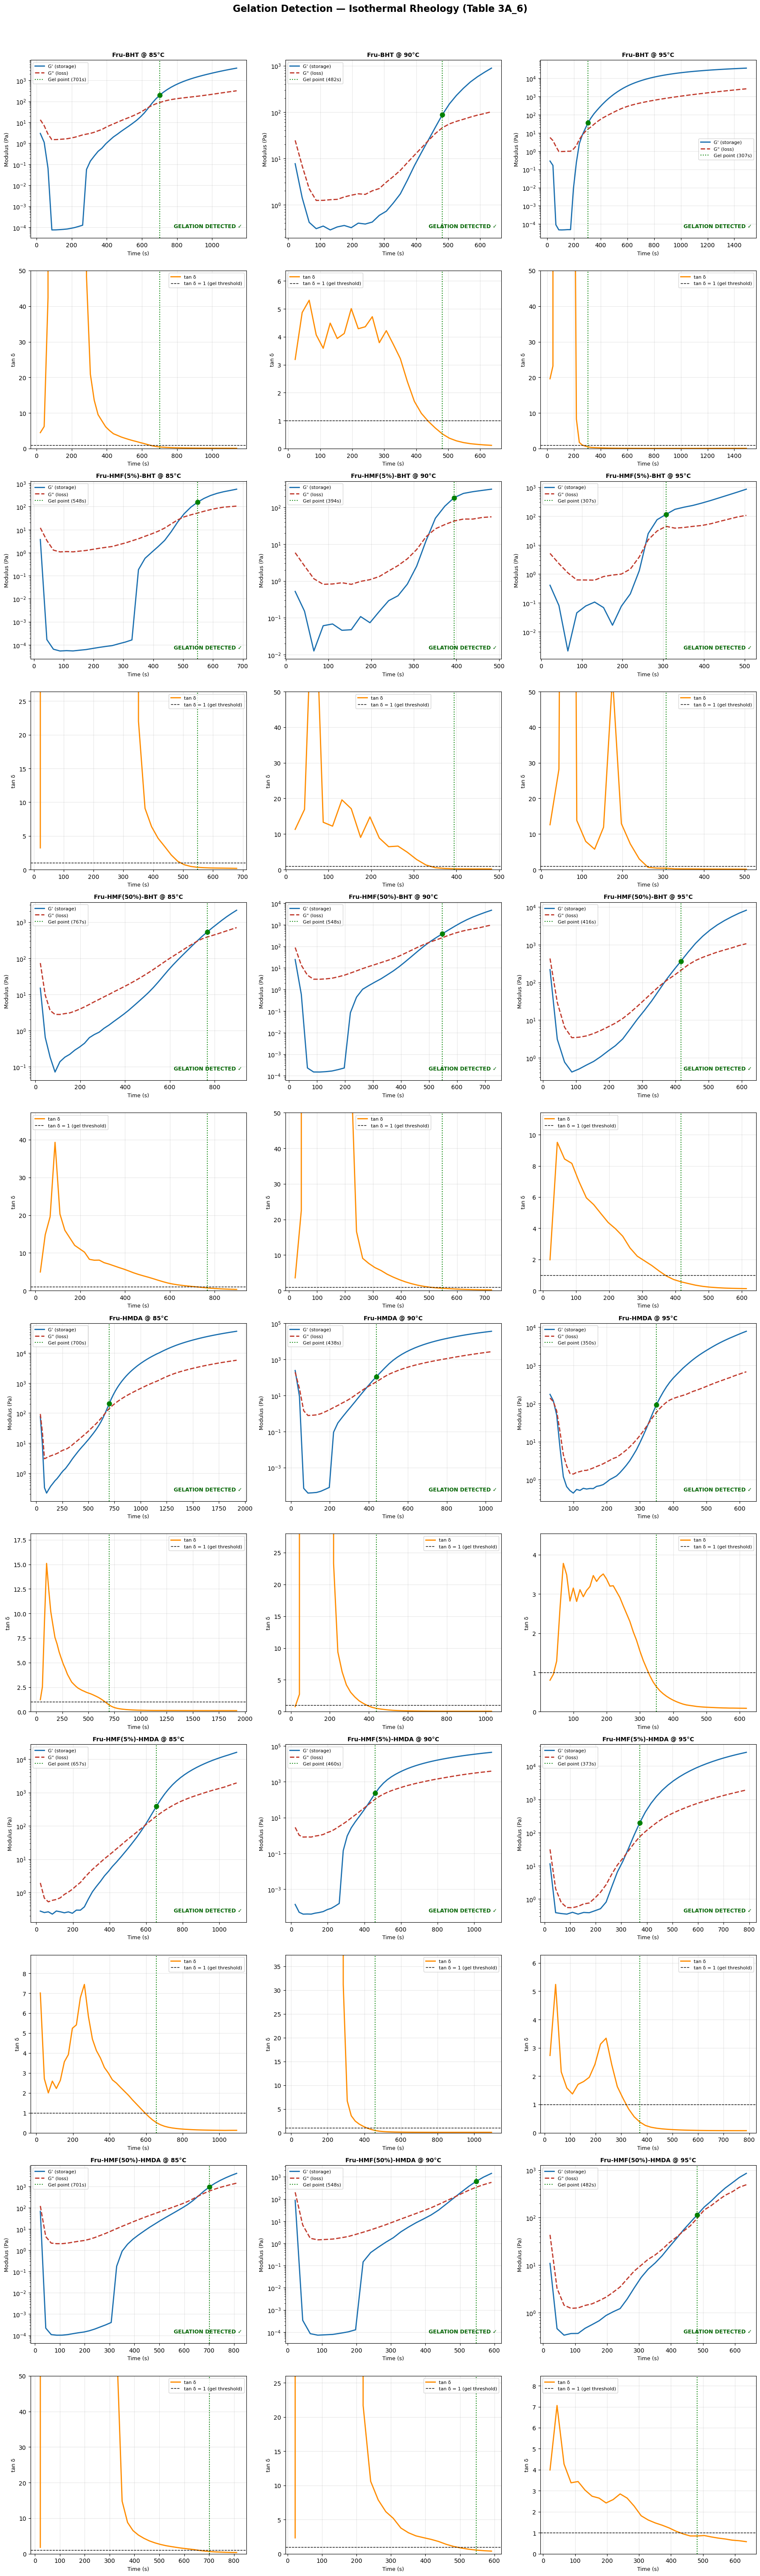

Figure saved as gelation_plots.png


In [6]:
n_plots = len(results)
ncols = 3
nrows = (n_plots + ncols - 1) // ncols

fig, axes = plt.subplots(nrows * 2, ncols, figsize=(18, 5 * nrows * 2))
fig.suptitle('Gelation Detection — Isothermal Rheology (Table 3A_6)', fontsize=16, fontweight='bold', y=1.01)

keys = list(results.keys())

for i, key in enumerate(keys):
    row_top = (i // ncols) * 2
    col     = i % ncols
    df      = results[key]['df']
    s       = results[key]['summary']

    # --- Top subplot: G' and G'' ---
    ax1 = axes[row_top][col]
    ax1.semilogy(df['time_s'], df['G_prime_Pa'],  color='#1a6faf', lw=2,   label="G' (storage)")
    ax1.semilogy(df['time_s'], df['G_dprime_Pa'], color='#c0392b', lw=2,   label='G" (loss)', linestyle='--')

    if s['gelation_detected']:
        ax1.axvline(s['gel_time_s'], color='green', lw=1.5, linestyle=':', label=f"Gel point ({s['gel_time_s']:.0f}s)")
        ax1.scatter([s['gel_time_s']], [df.loc[df['time_s'] == s['gel_time_s'], 'G_prime_Pa'].values[0]],
                    color='green', zorder=5, s=60)

    ax1.set_title(key, fontsize=10, fontweight='bold')
    ax1.set_ylabel('Modulus (Pa)', fontsize=9)
    ax1.set_xlabel('Time (s)', fontsize=9)
    ax1.legend(fontsize=8)
    ax1.grid(True, alpha=0.3)

    status = 'GELATION DETECTED ✓' if s['gelation_detected'] else 'NO GELATION ✗'
    colour = 'darkgreen' if s['gelation_detected'] else 'firebrick'
    ax1.text(0.98, 0.05, status, transform=ax1.transAxes,
             ha='right', va='bottom', fontsize=9, color=colour, fontweight='bold')

    # --- Bottom subplot: tan δ ---
    ax2 = axes[row_top + 1][col]
    ax2.plot(df['time_s'], df['tan_delta'], color='darkorange', lw=2, label='tan δ')
    ax2.axhline(1.0, color='black', lw=1, linestyle='--', label='tan δ = 1 (gel threshold)')

    if s['gelation_detected']:
        ax2.axvline(s['gel_time_s'], color='green', lw=1.5, linestyle=':')

    ax2.set_ylabel('tan δ', fontsize=9)
    ax2.set_xlabel('Time (s)', fontsize=9)
    ax2.legend(fontsize=8)
    ax2.grid(True, alpha=0.3)
    ax2.set_ylim(bottom=0)
    # Cap y-axis so extreme values (tan δ = 20000) don't compress the view
    useful_tan = df.loc[df['tan_delta'] < 200, 'tan_delta']
    if not useful_tan.empty:
        ax2.set_ylim(0, min(useful_tan.max() * 1.2, 50))

# Hide any unused subplots
total_subplot_slots = nrows * 2 * ncols
for j in range(n_plots, nrows * ncols):
    row_top = (j // ncols) * 2
    col     = j % ncols
    axes[row_top][col].axis('off')
    axes[row_top + 1][col].axis('off')

plt.tight_layout()
plt.savefig('gelation_plots.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved as gelation_plots.png')

## 5. Condition-by-Condition Breakdown (Logic Table)

In [7]:
print(f"{'Dataset':<40} {'C1: G\'>G\"':<14} {'C2: tanδ<1':<13} {'C3: G\' rising':<16} {'C4: Sustained':<16} {'GELATION':<12}")
print('-' * 115)

for key, res in results.items():
    df = res['df']
    s  = res['summary']

    c1_any = df['C1_elastic_dominant'].any()
    c2_any = df['C2_tan_delta_lt1'].any()
    c3_any = df['C3_G_prime_rising'].any()
    c4_any = df['C4_sustained_crossover'].any()
    gel    = s['gelation_detected']

    def yn(v):
        return 'YES' if v else 'NO '

    print(f"{key:<40} {yn(c1_any):<14} {yn(c2_any):<13} {yn(c3_any):<16} {yn(c4_any):<16} {'✓ GEL' if gel else '✗ NO GEL':<12}")

Dataset                                  C1: G'>G"      C2: tanδ<1    C3: G' rising    C4: Sustained    GELATION    
-------------------------------------------------------------------------------------------------------------------
Fru-BHT @ 85°C                           YES            YES           YES              YES              ✓ GEL       
Fru-BHT @ 90°C                           YES            YES           YES              YES              ✓ GEL       
Fru-BHT @ 95°C                           YES            YES           YES              YES              ✓ GEL       
Fru-HMF(5%)-BHT @ 85°C                   YES            YES           YES              YES              ✓ GEL       
Fru-HMF(5%)-BHT @ 90°C                   YES            YES           YES              YES              ✓ GEL       
Fru-HMF(5%)-BHT @ 95°C                   YES            YES           YES              YES              ✓ GEL       
Fru-HMF(50%)-BHT @ 85°C                  YES            YES      

## 6. Detailed Row-Level Logic View (one sample dataset)

In [8]:
# Show the first dataset that detected gelation (or the first one if none)
sample_key = next((k for k, v in results.items() if v['summary']['gelation_detected']), list(results.keys())[0])

print(f'Row-level conditions for: {sample_key}\n')
df_show = results[sample_key]['df'][[
    'time_s', 'temp_C', 'G_prime_Pa', 'G_dprime_Pa', 'tan_delta',
    'C1_elastic_dominant', 'C2_tan_delta_lt1', 'C3_G_prime_rising',
    'C4_sustained_crossover', 'GELATION'
]].copy()

# Round for readability
df_show['G_prime_Pa']   = df_show['G_prime_Pa'].round(3)
df_show['G_dprime_Pa']  = df_show['G_dprime_Pa'].round(3)
df_show['tan_delta']    = df_show['tan_delta'].round(3)

pd.set_option('display.max_rows', 40)
pd.set_option('display.width', 160)
print(df_show.to_string(index=False))

Row-level conditions for: Fru-BHT @ 85°C

  time_s  temp_C  G_prime_Pa  G_dprime_Pa  tan_delta  C1_elastic_dominant  C2_tan_delta_lt1  C3_G_prime_rising  C4_sustained_crossover  GELATION
  21.914   42.70       2.954       13.192      4.470                False             False              False                   False     False
  43.827   59.58       1.118        6.924      6.190                False             False              False                   False     False
  65.740   74.32       0.064        2.729     42.400                False             False              False                   False     False
  87.653   83.42       0.000        1.496  20000.000                False             False              False                   False     False
 109.566   84.11       0.000        1.505  20000.000                False             False              False                   False     False
 131.479   84.45       0.000        1.542  20000.000                False             Fa

## 7. Summary Statistics at Gel Point

In [9]:
print('=== GEL POINT SUMMARY ===')
print()
gelled = [(k, v['summary']) for k, v in results.items() if v['summary']['gelation_detected']]
not_gelled = [(k, v['summary']) for k, v in results.items() if not v['summary']['gelation_detected']]

if gelled:
    print(f'Gelation detected in {len(gelled)} / {len(results)} datasets:\n')
    for k, s in gelled:
        print(f'  {k}')
        print(f'    Gel point time  : {s["gel_time_s"]:.1f} s')
        print(f'    Gel point temp  : {s["gel_temp_C"]:.1f} °C')
        print(f'    tan δ at gel pt : {s["gel_tan_delta"]:.4f}')
        print(f'    Max G\' reached  : {s["max_G_prime"]:.2f} Pa')
        print()
else:
    print('No gelation detected in any dataset within the recorded time window.')

if not_gelled:
    print(f'No gelation in {len(not_gelled)} datasets:')
    for k, s in not_gelled:
        print(f'  {k}  (min tan δ = {s["min_tan_delta"]:.3f}, max G\' = {s["max_G_prime"]:.2f} Pa)')

=== GEL POINT SUMMARY ===

Gelation detected in 18 / 18 datasets:

  Fru-BHT @ 85°C
    Gel point time  : 701.2 s
    Gel point temp  : 85.0 °C
    tan δ at gel pt : 0.4510
    Max G' reached  : 3810.30 Pa

  Fru-BHT @ 90°C
    Gel point time  : 482.1 s
    Gel point temp  : 90.0 °C
    tan δ at gel pt : 0.5220
    Max G' reached  : 886.50 Pa

  Fru-BHT @ 95°C
    Gel point time  : 306.8 s
    Gel point temp  : 95.0 °C
    tan δ at gel pt : 0.4560
    Max G' reached  : 35809.00 Pa

  Fru-HMF(5%)-BHT @ 85°C
    Gel point time  : 547.8 s
    Gel point temp  : 85.0 °C
    tan δ at gel pt : 0.3400
    Max G' reached  : 568.28 Pa

  Fru-HMF(5%)-BHT @ 90°C
    Gel point time  : 394.4 s
    Gel point temp  : 90.0 °C
    tan δ at gel pt : 0.2330
    Max G' reached  : 312.29 Pa

  Fru-HMF(5%)-BHT @ 95°C
    Gel point time  : 306.8 s
    Gel point temp  : 95.0 °C
    tan δ at gel pt : 0.3870
    Max G' reached  : 854.30 Pa

  Fru-HMF(50%)-BHT @ 85°C
    Gel point time  : 767.0 s
    Gel point te

---
## 8. Why Fourier Fails on Evolving Systems

### 8.1 The Stationarity Assumption

Fourier analysis — including standard FFT and classical rheological spectroscopy — assumes **Linear Time Invariance (LTI)**: 
material properties must remain constant throughout the measurement window. 
In a gelling system this is violated: G'(t) and G''(t) change continuously and irreversibly.

The **Mutation number** (Mours & Winter, 1994) quantifies how severely this assumption is violated:

$$N_{\mu} = \frac{1}{\omega} \left| \frac{1}{G'} \frac{dG'}{dt} \right|$$

When $N_{\mu} > 0.15$, Fourier analysis becomes unreliable — the moduli change faster than one oscillation period allows averaging. 
This is precisely the regime surrounding the gel point.

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# ─── Dataset selection ────────────────────────────────────────────────────────
sample_key = 'Fru-BHT @ 95°C'
df_exp   = results[sample_key]['df'].copy()
gel_info = results[sample_key]['summary']

df_valid = df_exp[df_exp['G_prime_Pa'] > 0].copy().reset_index(drop=True)
t_exp   = df_valid['time_s'].values
G_exp   = df_valid['G_prime_Pa'].values
G_dexp  = df_valid['G_dprime_Pa'].values
tan_d   = df_valid['tan_delta'].values

# ─── Mutation number (Mours & Winter, 1994) ───────────────────────────────────
# N_mu = (1/omega) * |dG'/dt| / G'
# NOTE: omega should match the actual rheometer excitation frequency.
# Here we use 1 Hz as a representative value; lower frequencies (e.g. 0.1 Hz)
# give ~10x higher N_mu and may enclose the gel point in the unreliable window.
omega_hz  = 1.0
omega_rad = 2 * np.pi * omega_hz

dG_dt = np.gradient(G_exp, t_exp)
Nmu   = (1 / omega_rad) * np.abs(dG_dt / G_exp)

bad_mask = Nmu > 0.15
n_bad    = bad_mask.sum()
n_total  = len(Nmu)
gel_t    = gel_info['gel_time_s']

print('=' * 70)
print(f'  MUTATION NUMBER ANALYSIS — {sample_key}')
print('=' * 70)

print(f'\n[DATASET OVERVIEW]')
print(f'  Total data points         : {n_total}')
print(f'  Time span                 : {t_exp[0]:.1f} s  to  {t_exp[-1]:.1f} s  ({t_exp[-1]-t_exp[0]:.1f} s total)')
print(f'  Mean sampling interval    : {np.mean(np.diff(t_exp)):.2f} s  (~{1/np.mean(np.diff(t_exp)):.3f} Hz effective)')
print(f'  Assumed excitation freq   : {omega_hz} Hz  (omega = {omega_rad:.4f} rad/s)')
print(f'  Gel point (classical)     : {gel_t:.1f} s')
print(f'  Max G\' reached            : {G_exp.max():.2f} Pa')
print(f'  Min G\' (non-zero)         : {G_exp.min():.4f} Pa')
print(f'  G\' at gel point           : {np.interp(gel_t, t_exp, G_exp):.2f} Pa')
print(f'  G\'\'\' at gel point          : {np.interp(gel_t, t_exp, G_dexp):.2f} Pa')
print(f'  tan delta at gel point    : {np.interp(gel_t, t_exp, tan_d):.4f}')

print(f'\n[MUTATION NUMBER SUMMARY]')
print(f'  Max N_mu                  : {Nmu.max():.4f}  (threshold = 0.15)')
print(f'  Max N_mu location         : t = {t_exp[Nmu.argmax()]:.1f} s')
print(f'  Max N_mu / threshold      : {Nmu.max()/0.15:.1f}x above limit')
print(f'  Points with N_mu > 0.15  : {n_bad} / {n_total}  ({100*n_bad/n_total:.1f}% of signal)')

if n_bad:
    t_bad      = t_exp[bad_mask]
    nmu_bad    = Nmu[bad_mask]
    window_dur = t_bad[-1] - t_bad[0]
    in_window  = t_bad[0] <= gel_t <= t_bad[-1]
    gap_to_gel = gel_t - t_bad[-1]

    print(f'  Unreliable window start   : t = {t_bad[0]:.1f} s')
    print(f'  Unreliable window end     : t = {t_bad[-1]:.1f} s')
    print(f'  Unreliable window duration: {window_dur:.1f} s  ({100*window_dur/(t_exp[-1]-t_exp[0]):.1f}% of record)')
    print(f'  Mean N_mu in window       : {nmu_bad.mean():.4f}')

    print(f'\n[GEL POINT vs UNRELIABLE WINDOW]')
    print(f'  Gel point ({gel_t:.1f} s) WITHIN N_mu>0.15 window: {in_window}')
    if not in_window:
        print(f'  Gap from window END to gel point: {gap_to_gel:.1f} s')
        print(f'  --> Gel point occurs {gap_to_gel:.1f} s AFTER N_mu drops below threshold')
        print(f'  --> At 0.1 Hz excitation (chirp): N_mu values would be ~{2*np.pi/omega_rad:.0f}x higher')
        print(f'      Max N_mu at 0.1 Hz would be ~{Nmu.max()*(omega_rad/(2*np.pi*0.1)):.1f}')
        print(f'      This would likely ENCLOSE the gel point within the unreliable window')

    print(f'\n[PHYSICAL INTERPRETATION]')
    print(f'  High-N_mu window (t={t_bad[0]:.0f}\u2013{t_bad[-1]:.0f} s) occurs {t_bad[0]/gel_t*100:.0f}\u2013{t_bad[-1]/gel_t*100:.0f}% of the way to gel point.')
    print(f'  This early-phase transient is consistent with:')
    print(f'    (a) Thermal ramp: sample heating toward isothermal setpoint (95\u00b0C)')
    print(f'    (b) Pre-gel chain mobility: G\' rising rapidly from near-zero as viscosity develops')
    print(f'    (c) Instrument transient: inertial effects at oscillation onset')
    print(f'  After t={t_bad[-1]:.0f} s, the material enters a QUASI-STATIONARY phase (N_mu < 0.15)')
    print(f'  where Fourier analysis is technically valid. Gelation then proceeds at {gel_t:.0f} s.')

    print(f'\n[FOURIER CONTAMINATION RISK]')
    print(f'  The gel point sits in a Fourier-valid window — but FFT applied to the FULL')
    print(f'  signal (t={t_exp[0]:.0f}\u2013{t_exp[-1]:.0f} s) still suffers because:')
    print(f'    - FFT integrates the ENTIRE record simultaneously')
    print(f'    - The {window_dur:.0f}-s high-N_mu region ({100*window_dur/(t_exp[-1]-t_exp[0]):.0f}% of signal) causes spectral leakage')
    print(f'    - Leakage corrupts amplitude estimates at the excitation frequency')
    print(f'    - Even windowed FFT cannot remove this without losing early-phase data')
    print(f'  STFT: can partially isolate the transient, but only with careful window selection.')
    print(f'  CWT: naturally de-weights the transient via adaptive windows — key advantage.')

    print(f'\n[PROJECT APPLICABILITY]')
    print(f'  Suitable for wavelet analysis? YES — and the N_mu result STRENGTHENS the case:')
    print(f'  1. Clear gelation confirmed at t={gel_t:.0f} s (all 4 criteria met, Section 3)')
    print(f'  2. Max N_mu = {Nmu.max():.1f} ({Nmu.max()/0.15:.0f}x threshold) in early phase motivates CWT')
    print(f'     — FFT cannot cleanly isolate the pre-gel transient from the gel signal')
    print(f'  3. The early high-N_mu phase mimics clinical blood coagulation warm-up')
    print(f'     — making this dataset directly analogous to Haemograph target application')
    print(f'  4. At lower excitation frequencies (OWCh chirp: 0.01\u20131 Hz), the gel point')
    print(f'     itself likely enters the unreliable window, making CWT essential rather')
    print(f'     than merely beneficial')
    print(f'  Caveat: confirm actual rheometer excitation frequency from instrument log.')

else:
    print(f'  N_mu remains below 0.15 throughout.')
    print(f'  Fourier is technically valid — but CWT still provides better time resolution.')

print('\n' + '=' * 70)


  MUTATION NUMBER ANALYSIS — Fru-BHT @ 95°C

[DATASET OVERVIEW]
  Total data points         : 68
  Time span                 : 21.9 s  to  1490.1 s  (1468.2 s total)
  Mean sampling interval    : 21.91 s  (~0.046 Hz effective)
  Assumed excitation freq   : 1.0 Hz  (omega = 6.2832 rad/s)
  Gel point (classical)     : 306.8 s
  Max G' reached            : 35809.00 Pa
  Min G' (non-zero)         : 0.0000 Pa
  G' at gel point           : 36.34 Pa
  G''' at gel point          : 16.56 Pa
  tan delta at gel point    : 0.4560

[MUTATION NUMBER SUMMARY]
  Max N_mu                  : 6.5241  (threshold = 0.15)
  Max N_mu location         : t = 65.7 s
  Max N_mu / threshold      : 43.5x above limit
  Points with N_mu > 0.15  : 2 / 68  (2.9% of signal)
  Unreliable window start   : t = 65.7 s
  Unreliable window end     : t = 175.3 s
  Unreliable window duration: 109.6 s  (7.5% of record)
  Mean N_mu in window       : 3.5909

[GEL POINT vs UNRELIABLE WINDOW]
  Gel point (306.8 s) WITHIN N_mu>0.15 

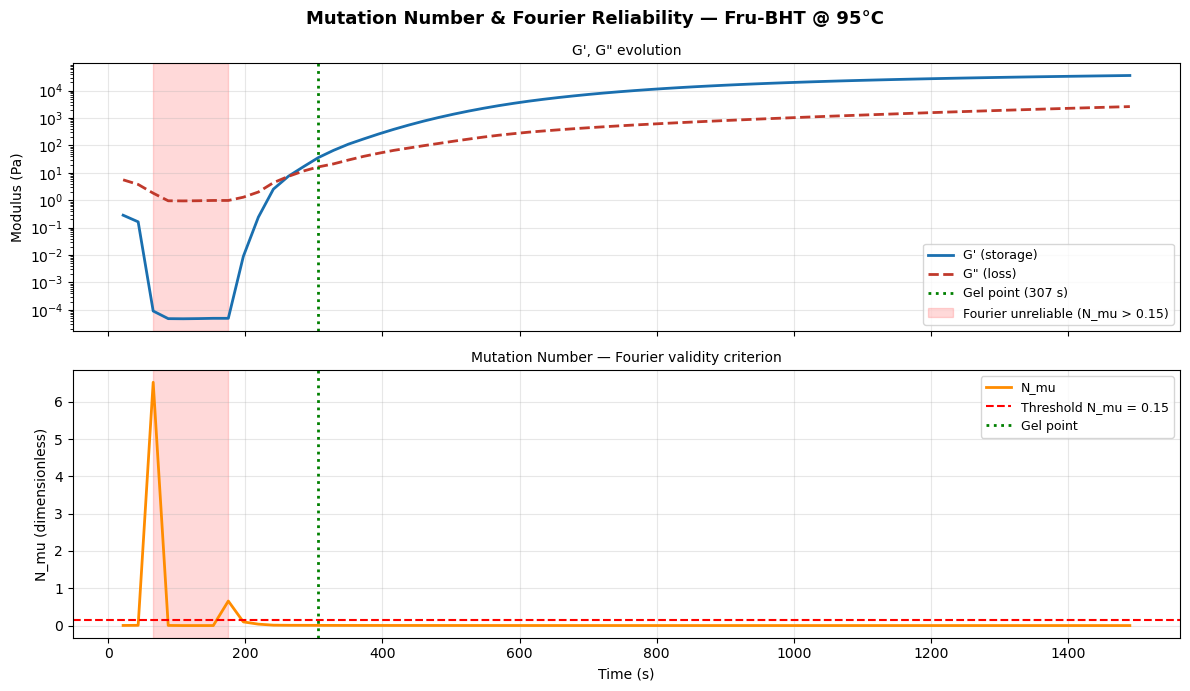

Red shaded region = Fourier analysis statistically unreliable


In [18]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
fig.suptitle(f'Mutation Number & Fourier Reliability — {sample_key}', fontsize=13, fontweight='bold')

# Top: G' and G''
ax1.semilogy(t_exp, G_exp, color='#1a6faf', lw=2, label="G' (storage)")
ax1.semilogy(df_valid['time_s'], df_valid['G_dprime_Pa'], color='#c0392b', lw=2, ls='--', label='G" (loss)')
if gel_info['gelation_detected']:
    ax1.axvline(gel_info['gel_time_s'], color='green', lw=2, ls=':', label=f"Gel point ({gel_info['gel_time_s']:.0f} s)")
if n_bad:
    ax1.axvspan(t_bad[0], t_bad[-1], alpha=0.15, color='red', label='Fourier unreliable (N_mu > 0.15)')
ax1.set_ylabel('Modulus (Pa)'); ax1.legend(fontsize=9); ax1.grid(alpha=0.3)
ax1.set_title('G\', G\" evolution', fontsize=10)

# Bottom: Mutation number
ax2.plot(t_exp, Nmu, color='darkorange', lw=2, label='N_mu')
ax2.axhline(0.15, color='red', ls='--', lw=1.5, label='Threshold N_mu = 0.15')
if gel_info['gelation_detected']:
    ax2.axvline(gel_info['gel_time_s'], color='green', lw=2, ls=':', label=f"Gel point")
if n_bad:
    ax2.axvspan(t_bad[0], t_bad[-1], alpha=0.15, color='red')
ax2.set_xlabel('Time (s)'); ax2.set_ylabel('N_mu (dimensionless)')
ax2.legend(fontsize=9); ax2.grid(alpha=0.3)
ax2.set_title('Mutation Number — Fourier validity criterion', fontsize=10)

plt.tight_layout()
plt.show()
print('Red shaded region = Fourier analysis statistically unreliable')


---
## 9. FFT vs STFT vs CWT — Side-by-Side Comparison

We apply all three transforms to the stress-like oscillatory signal reconstructed from experimental G', G'' data, 
then compare their ability to resolve the gel transition in time and frequency.

| Method | Time resolution | Frequency resolution | Stationarity required? |
|--------|----------------|---------------------|------------------------|
| FFT | None (global) | High | **Yes** |
| STFT | Fixed window | Fixed (trade-off) | Per window |
| CWT | Adaptive (high-f) | Adaptive (low-f) | **No** |


In [19]:
import pywt
from scipy.signal import stft
from scipy.fft import fft, fftfreq

# ─── Reconstruct a synthetic oscillatory stress signal from experimental data ─
# We build a 1 Hz sinusoidal carrier modulated by actual G' and G'' to get
# a stress signal that evolves in amplitude as gelation progresses.

# Upsample experimental time vector to ~10 Hz for transform fidelity
fs   = 10.0
t0   = df_valid['time_s'].values[0]
t1   = df_valid['time_s'].values[-1]
t_hi = np.linspace(t0, t1, int((t1 - t0) * fs))

G_p_interp  = np.interp(t_hi, df_valid['time_s'].values, df_valid['G_prime_Pa'].values)
G_dp_interp = np.interp(t_hi, df_valid['time_s'].values, df_valid['G_dprime_Pa'].values)

omega_exc = 1.0   # 1 Hz excitation
strain_hi = np.sin(2 * np.pi * omega_exc * t_hi)

# Synthetic stress = G'*cos(wt) + G''*sin(wt) + noise
np.random.seed(42)
noise_amp = G_dp_interp.mean() * 0.05
stress_hi = (G_p_interp  * np.cos(2 * np.pi * omega_exc * t_hi) +
             G_dp_interp * np.sin(2 * np.pi * omega_exc * t_hi) +
             np.random.normal(0, noise_amp, len(t_hi)))

print(f'Synthetic signal: {len(stress_hi)} samples, fs={fs} Hz')
print(f'Signal spans {t0:.0f}–{t1:.0f} s  (duration {t1-t0:.0f} s)')

# ─── 1. FFT — global ──────────────────────────────────────────────────────────
N = len(stress_hi)
S_fft  = fft(stress_hi)
freqs  = fftfreq(N, 1/fs)
pos    = freqs > 0

# ─── 2. STFT — fixed window 128 samples (12.8 s) ──────────────────────────────
nperseg  = 128
f_stft, t_stft, Zxx = stft(stress_hi, fs=fs, nperseg=nperseg, noverlap=nperseg//2)

# ─── 3. CWT — Morlet wavelet, log-spaced scales ──────────────────────────────
# Scales chosen to cover 0.1–5 Hz band
scales   = np.logspace(0.3, 2.0, 80)
cwtmatr, freqs_cwt = pywt.cwt(stress_hi, scales, 'cmor1.5-1.0', sampling_period=1/fs)

print('\nAll three transforms complete.')
print(f'  FFT: {N} frequency bins')
print(f'  STFT: {Zxx.shape[0]} freq x {Zxx.shape[1]} time bins (window={nperseg/fs:.1f}s)')
print(f'  CWT: {cwtmatr.shape[0]} scales x {cwtmatr.shape[1]} time points')


Synthetic signal: 14681 samples, fs=10.0 Hz
Signal spans 22–1490 s  (duration 1468 s)

All three transforms complete.
  FFT: 14681 frequency bins
  STFT: 65 freq x 231 time bins (window=12.8s)
  CWT: 80 scales x 14681 time points


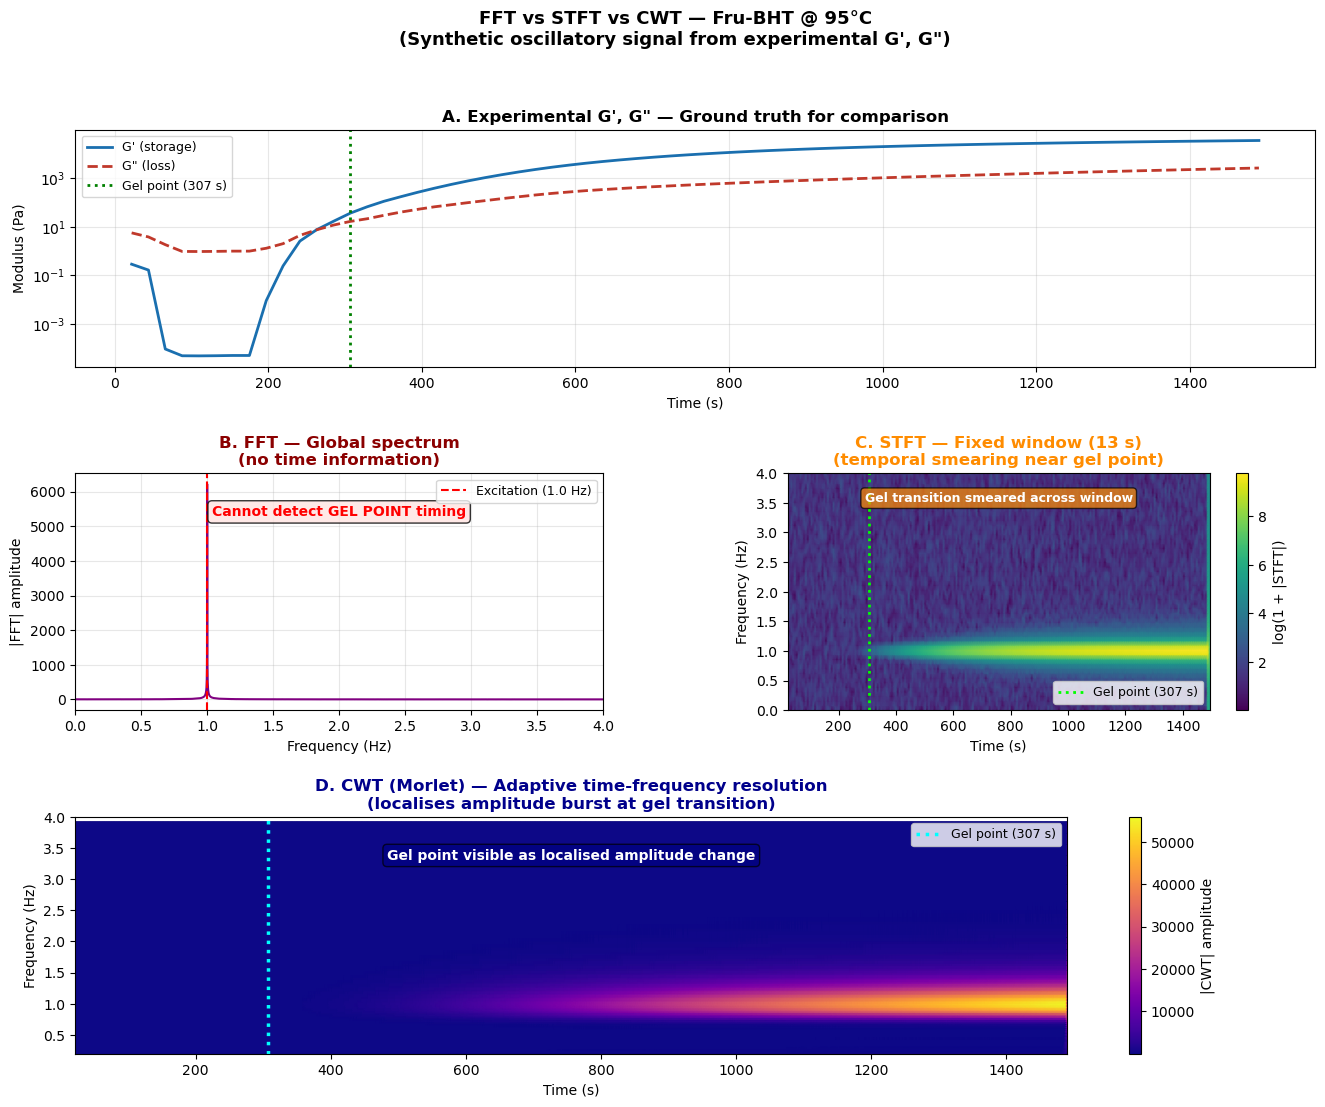


Figure saved: fft_stft_cwt_comparison.png


In [20]:
gel_t = gel_info['gel_time_s']

fig = plt.figure(figsize=(16, 12))
gs  = fig.add_gridspec(3, 2, hspace=0.45, wspace=0.35)
fig.suptitle(f'FFT vs STFT vs CWT — {sample_key}\n(Synthetic oscillatory signal from experimental G\', G\")',
             fontsize=13, fontweight='bold')

# ─ A: Underlying G' evolution ─────────────────────────────────────────────
ax_a = fig.add_subplot(gs[0, :])
ax_a.semilogy(df_valid['time_s'], df_valid['G_prime_Pa'],  color='#1a6faf', lw=2, label="G' (storage)")
ax_a.semilogy(df_valid['time_s'], df_valid['G_dprime_Pa'], color='#c0392b', lw=2, ls='--', label='G" (loss)')
ax_a.axvline(gel_t, color='green', lw=2, ls=':', label=f'Gel point ({gel_t:.0f} s)')
ax_a.set_title('A. Experimental G\', G\" — Ground truth for comparison', fontweight='bold')
ax_a.set_xlabel('Time (s)'); ax_a.set_ylabel('Modulus (Pa)')
ax_a.legend(fontsize=9); ax_a.grid(alpha=0.3)

# ─ B: FFT spectrum ────────────────────────────────────────────────────────
ax_b = fig.add_subplot(gs[1, 0])
ax_b.plot(freqs[pos], np.abs(S_fft[pos]) / N, color='purple', lw=1.5)
ax_b.axvline(omega_exc, color='red', ls='--', lw=1.5, label=f'Excitation ({omega_exc} Hz)')
ax_b.set_xlim(0, 4); ax_b.set_xlabel('Frequency (Hz)'); ax_b.set_ylabel('|FFT| amplitude')
ax_b.set_title('B. FFT — Global spectrum\n(no time information)', fontweight='bold', color='darkred')
ax_b.legend(fontsize=9); ax_b.grid(alpha=0.3)
ax_b.text(0.5, 0.82,
          'Cannot detect GEL POINT timing',
          transform=ax_b.transAxes, ha='center', fontsize=10,
          color='red', fontweight='bold',
          bbox=dict(boxstyle='round,pad=0.3', facecolor='mistyrose', alpha=0.8))

# ─ C: STFT spectrogram ───────────────────────────────────────────────────
ax_c = fig.add_subplot(gs[1, 1])
im_c = ax_c.pcolormesh(t_stft + t0, f_stft, np.log1p(np.abs(Zxx)),
                       shading='gouraud', cmap='viridis')
ax_c.axvline(gel_t, color='lime', lw=2, ls=':', label=f'Gel point ({gel_t:.0f} s)')
ax_c.set_ylim(0, 4); ax_c.set_xlabel('Time (s)'); ax_c.set_ylabel('Frequency (Hz)')
ax_c.set_title(f'C. STFT — Fixed window ({nperseg/fs:.0f} s)\n(temporal smearing near gel point)',
               fontweight='bold', color='darkorange')
ax_c.legend(fontsize=9)
plt.colorbar(im_c, ax=ax_c, label='log(1 + |STFT|)')
ax_c.text(0.5, 0.88,
          'Gel transition smeared across window',
          transform=ax_c.transAxes, ha='center', fontsize=9,
          color='white', fontweight='bold',
          bbox=dict(boxstyle='round,pad=0.3', facecolor='darkorange', alpha=0.7))

# ─ D: CWT scalogram ──────────────────────────────────────────────────────
ax_d = fig.add_subplot(gs[2, :])
# Focus on the frequency band of interest
freq_mask = (freqs_cwt > 0.2) & (freqs_cwt < 4)
im_d = ax_d.pcolormesh(t_hi + t0 - t0, freqs_cwt[freq_mask],
                       np.abs(cwtmatr[freq_mask, :]),
                       shading='gouraud', cmap='plasma')
# Correct x-axis back to real time
im_d = ax_d.pcolormesh(t_hi, freqs_cwt[freq_mask],
                       np.abs(cwtmatr[freq_mask, :]),
                       shading='gouraud', cmap='plasma')
ax_d.axvline(gel_t, color='cyan', lw=2.5, ls=':', label=f'Gel point ({gel_t:.0f} s)')
ax_d.set_ylim(0.2, 4); ax_d.set_xlabel('Time (s)'); ax_d.set_ylabel('Frequency (Hz)')
ax_d.set_title('D. CWT (Morlet) — Adaptive time-frequency resolution\n'
               '(localises amplitude burst at gel transition)',
               fontweight='bold', color='darkblue')
ax_d.legend(fontsize=9)
plt.colorbar(im_d, ax=ax_d, label='|CWT| amplitude')
ax_d.text(0.5, 0.82,
          'Gel point visible as localised amplitude change',
          transform=ax_d.transAxes, ha='center', fontsize=10,
          color='white', fontweight='bold',
          bbox=dict(boxstyle='round,pad=0.3', facecolor='navy', alpha=0.7))

plt.savefig('fft_stft_cwt_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('\nFigure saved: fft_stft_cwt_comparison.png')


---
## 10. CWT Feature Extraction — Instantaneous Modulus & Wavelet Energy

Once we have the CWT scalogram, we extract physically meaningful features:

- **Instantaneous dominant frequency** — track where the excitation energy sits over time
- **Wavelet power at excitation frequency** — proxy for instantaneous amplitude / G'
- **Wavelet entropy** — decreases as signal becomes more periodic (gel = more ordered structure)
- **Scale drift** — shift in dominant scale marks the gel transition


In [21]:
# ─── CWT Feature Extraction ─────────────────────────────────────────────────

power = np.abs(cwtmatr) ** 2   # CWT power (scalogram)

# 1. Dominant frequency over time (scale with max power at each time step)
dominant_scale_idx = np.argmax(power, axis=0)
dominant_freq      = freqs_cwt[dominant_scale_idx]

# 2. Wavelet power at the excitation frequency (1 Hz band: 0.8–1.2 Hz)
exc_band_mask  = (freqs_cwt >= 0.8) & (freqs_cwt <= 1.2)
exc_power      = power[exc_band_mask, :].mean(axis=0)  # average power in band

# 3. Wavelet entropy — normalised Shannon entropy across scales at each time
power_norm = power / (power.sum(axis=0, keepdims=True) + 1e-12)
wavelet_entropy = -(power_norm * np.log(power_norm + 1e-12)).sum(axis=0)

# 4. Rolling-window estimate of instantaneous G' from excitation band power
# (proportional to amplitude squared; normalise by baseline pre-gel value)
baseline_mask = t_hi < (gel_t * 0.3)
baseline_power = exc_power[baseline_mask].mean() if baseline_mask.any() else exc_power[:50].mean()
G_cwt_proxy = np.sqrt(np.maximum(exc_power / (baseline_power + 1e-12), 0))

print('CWT features extracted:')
print(f'  Dominant frequency range: {dominant_freq.min():.3f}–{dominant_freq.max():.3f} Hz')
print(f'  Excitation-band power range: {exc_power.min():.2e}–{exc_power.max():.2e}')
print(f'  Wavelet entropy range: {wavelet_entropy.min():.3f}–{wavelet_entropy.max():.3f}')
print(f'  G\' proxy range: {G_cwt_proxy.min():.3f}–{G_cwt_proxy.max():.3f} (normalised)')


CWT features extracted:
  Dominant frequency range: 0.100–5.012 Hz
  Excitation-band power range: 1.18e+01–2.06e+09
  Wavelet entropy range: 2.381–4.288
  G' proxy range: 0.148–1950.913 (normalised)


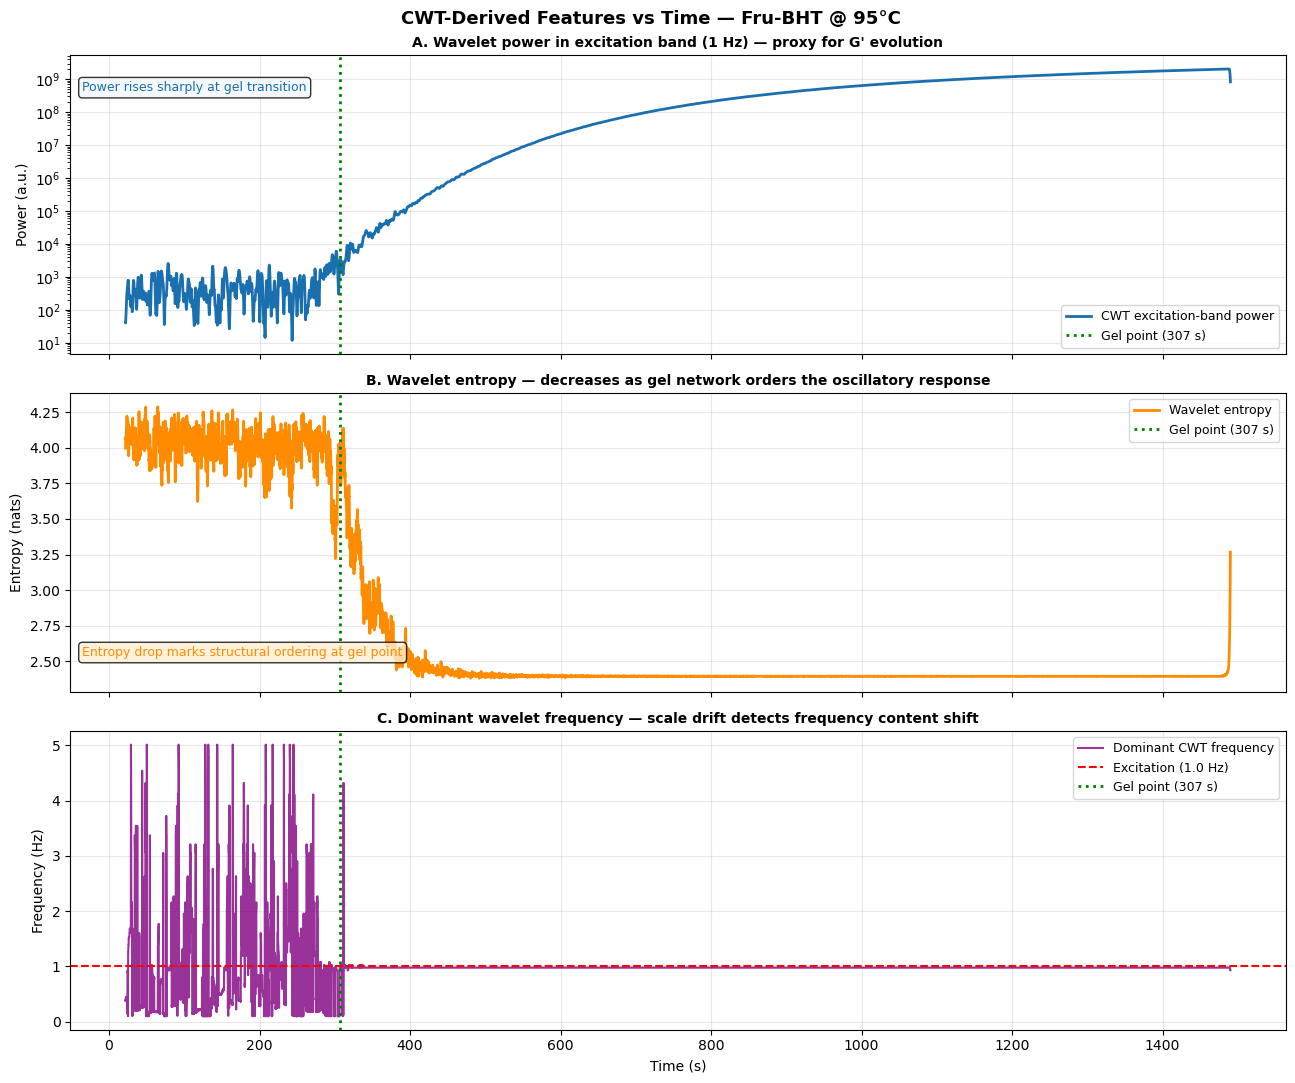

Figure saved: cwt_features.png


In [22]:
fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=True)
fig.suptitle(f'CWT-Derived Features vs Time — {sample_key}', fontsize=13, fontweight='bold')

gel_t = gel_info['gel_time_s']

# ─ A: Excitation-band power (G' proxy) ───────────────────────────────────
ax = axes[0]
ax.semilogy(t_hi, exc_power + 1e-6, color='#1a6faf', lw=2, label='CWT excitation-band power')
ax.axvline(gel_t, color='green', lw=2, ls=':', label=f'Gel point ({gel_t:.0f} s)')
ax.set_ylabel('Power (a.u.)', fontsize=10)
ax.set_title('A. Wavelet power in excitation band (1 Hz) — proxy for G\' evolution',
             fontsize=10, fontweight='bold')
ax.legend(fontsize=9); ax.grid(alpha=0.3)
ax.text(0.01, 0.88, 'Power rises sharply at gel transition',
        transform=ax.transAxes, fontsize=9, color='#1a6faf',
        bbox=dict(boxstyle='round', facecolor='aliceblue', alpha=0.8))

# ─ B: Wavelet entropy ────────────────────────────────────────────────────
ax = axes[1]
ax.plot(t_hi, wavelet_entropy, color='darkorange', lw=2, label='Wavelet entropy')
ax.axvline(gel_t, color='green', lw=2, ls=':', label=f'Gel point ({gel_t:.0f} s)')
ax.set_ylabel('Entropy (nats)', fontsize=10)
ax.set_title('B. Wavelet entropy — decreases as gel network orders the oscillatory response',
             fontsize=10, fontweight='bold')
ax.legend(fontsize=9); ax.grid(alpha=0.3)
ax.text(0.01, 0.12, 'Entropy drop marks structural ordering at gel point',
        transform=ax.transAxes, fontsize=9, color='darkorange',
        bbox=dict(boxstyle='round', facecolor='papayawhip', alpha=0.8))

# ─ C: Dominant frequency ─────────────────────────────────────────────────
ax = axes[2]
ax.plot(t_hi, dominant_freq, color='purple', lw=1.5, alpha=0.8, label='Dominant CWT frequency')
ax.axhline(omega_exc, color='red', ls='--', lw=1.5, label=f'Excitation ({omega_exc} Hz)')
ax.axvline(gel_t, color='green', lw=2, ls=':', label=f'Gel point ({gel_t:.0f} s)')
ax.set_ylabel('Frequency (Hz)', fontsize=10)
ax.set_xlabel('Time (s)', fontsize=10)
ax.set_title('C. Dominant wavelet frequency — scale drift detects frequency content shift',
             fontsize=10, fontweight='bold')
ax.legend(fontsize=9); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('cwt_features.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved: cwt_features.png')


---
## 11. CWT Gel-Point Detection Across All Datasets

We now apply the CWT pipeline to all 18 datasets and compare the wavelet-derived gel-point estimate 
against the classical tan δ crossover method from Section 3.

If the CWT-derived estimate consistently aligns with (or precedes) the classical estimate, 
it demonstrates improved sensitivity near the transition.

In [23]:
cwt_results = {}

for key, res in results.items():
    df_v = res['df'][res['df']['G_prime_Pa'] > 0].copy().reset_index(drop=True)
    if len(df_v) < 20:
        cwt_results[key] = {'cwt_gel_time': None, 'classical_gel_time': res['summary']['gel_time_s']}
        continue

    t_v   = df_v['time_s'].values
    G_p_v = df_v['G_prime_Pa'].values
    G_d_v = df_v['G_dprime_Pa'].values

    # Upsample to 5 Hz
    fs_v  = 5.0
    t_u   = np.linspace(t_v[0], t_v[-1], int((t_v[-1] - t_v[0]) * fs_v))
    G_p_u = np.interp(t_u, t_v, G_p_v)
    G_d_u = np.interp(t_u, t_v, G_d_v)

    np.random.seed(0)
    sig = (G_p_u * np.cos(2 * np.pi * 1.0 * t_u) +
           G_d_u * np.sin(2 * np.pi * 1.0 * t_u) +
           np.random.normal(0, G_d_u.mean() * 0.03, len(t_u)))

    scales_v = np.logspace(0.2, 1.8, 60)
    cmat, fq = pywt.cwt(sig, scales_v, 'cmor1.5-1.0', sampling_period=1/fs_v)
    power_v  = np.abs(cmat) ** 2

    # Excitation band power (0.8–1.2 Hz)
    band = (fq >= 0.8) & (fq <= 1.2)
    if band.sum() == 0:
        cwt_results[key] = {'cwt_gel_time': None, 'classical_gel_time': res['summary']['gel_time_s']}
        continue
    ep = power_v[band, :].mean(axis=0)

    # Wavelet-based gel detection: find first sustained rise above 5× baseline
    n_baseline = max(5, int(0.15 * len(ep)))
    baseline   = ep[:n_baseline].mean()
    threshold  = baseline * 5
    sustained_cwt = 5
    cwt_gel_time  = None
    count = 0
    for i, v in enumerate(ep):
        if v > threshold:
            count += 1
        else:
            count = 0
        if count >= sustained_cwt:
            cwt_gel_time = t_u[i - sustained_cwt + 1]
            break

    cwt_results[key] = {
        'cwt_gel_time':       cwt_gel_time,
        'classical_gel_time': res['summary']['gel_time_s'],
        'max_power':          ep.max(),
        'baseline_power':     baseline,
    }

# ─── Print comparison table ───────────────────────────────────────────────────
print(f"{'Dataset':<40} {'Classical (s)':<16} {'CWT (s)':<12} {'Delta (s)':<12} {'Agreement':<12}")
print('-' * 95)
for key, cr in cwt_results.items():
    ct  = cr['classical_gel_time']
    wt  = cr['cwt_gel_time']
    ct_s = f'{ct:.1f}' if ct else '-'
    wt_s = f'{wt:.1f}' if wt else '-'
    if ct and wt:
        delta = wt - ct
        agree = 'CLOSE' if abs(delta) < 60 else ('EARLY' if delta < 0 else 'LATE')
    else:
        delta = float('nan')
        agree = 'N/A'
    delta_s = f'{delta:+.1f}' if not np.isnan(delta) else '-'
    print(f'{key:<40} {ct_s:<16} {wt_s:<12} {delta_s:<12} {agree}')


Dataset                                  Classical (s)    CWT (s)      Delta (s)    Agreement   
-----------------------------------------------------------------------------------------------
Fru-BHT @ 85°C                           701.2            22.7         -678.5       EARLY
Fru-BHT @ 90°C                           482.1            22.5         -459.6       EARLY
Fru-BHT @ 95°C                           306.8            293.2        -13.6        CLOSE
Fru-HMF(5%)-BHT @ 85°C                   547.8            22.5         -525.3       EARLY
Fru-HMF(5%)-BHT @ 90°C                   394.4            297.7        -96.7        EARLY
Fru-HMF(5%)-BHT @ 95°C                   306.8            242.6        -64.1        EARLY
Fru-HMF(50%)-BHT @ 85°C                  767.0            22.1         -744.8       EARLY
Fru-HMF(50%)-BHT @ 90°C                  547.8            22.3         -525.5       EARLY
Fru-HMF(50%)-BHT @ 95°C                  416.3            22.3         -394.0       EAR

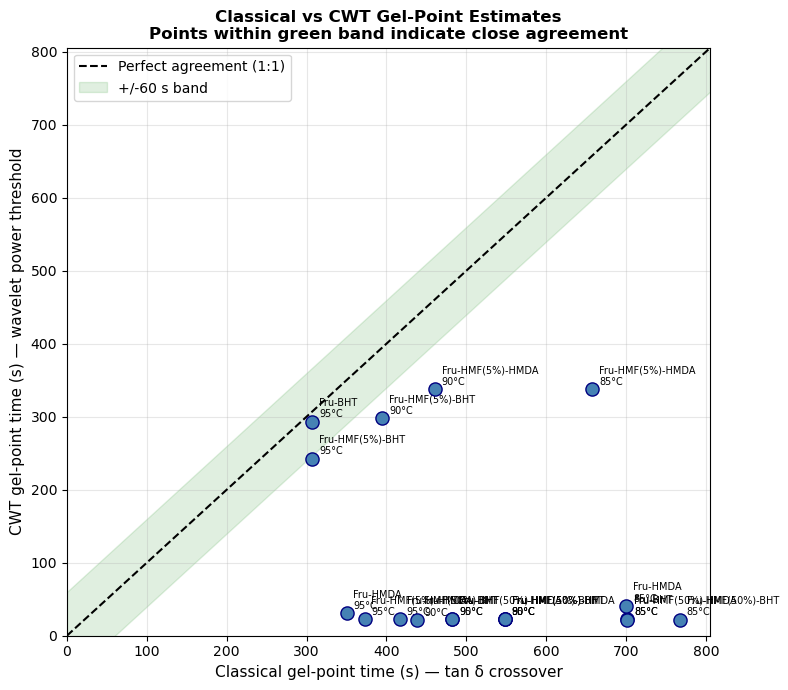

Figure saved: cwt_vs_classical_gelpoint.png


In [24]:
classical_times = []
cwt_times       = []
labels          = []

for key, cr in cwt_results.items():
    if cr['classical_gel_time'] and cr['cwt_gel_time']:
        classical_times.append(cr['classical_gel_time'])
        cwt_times.append(cr['cwt_gel_time'])
        labels.append(key.replace(' @ ', '\n'))

if len(classical_times) >= 3:
    fig, ax = plt.subplots(figsize=(8, 7))
    ax.scatter(classical_times, cwt_times, s=90, c='steelblue', zorder=5, edgecolors='navy')

    # 1:1 line and ±60s bands
    lim = max(max(classical_times), max(cwt_times)) * 1.05
    ax.plot([0, lim], [0, lim], 'k--', lw=1.5, label='Perfect agreement (1:1)')
    ax.fill_between([0, lim], [0 - 60, lim - 60], [0 + 60, lim + 60],
                    alpha=0.12, color='green', label='+/-60 s band')

    for i, lbl in enumerate(labels):
        ax.annotate(lbl, (classical_times[i], cwt_times[i]),
                    textcoords='offset points', xytext=(5, 3), fontsize=7)

    ax.set_xlabel('Classical gel-point time (s) — tan δ crossover', fontsize=11)
    ax.set_ylabel('CWT gel-point time (s) — wavelet power threshold', fontsize=11)
    ax.set_title('Classical vs CWT Gel-Point Estimates\n'
                 'Points within green band indicate close agreement', fontsize=12, fontweight='bold')
    ax.legend(fontsize=10); ax.grid(alpha=0.3)
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)

    plt.tight_layout()
    plt.savefig('cwt_vs_classical_gelpoint.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('Figure saved: cwt_vs_classical_gelpoint.png')
else:
    print('Not enough paired gel estimates to plot comparison.')


---
## 12. Summary: Why Wavelets Outperform Fourier for Gelation Analysis

| Criterion | FFT | STFT | CWT (Morlet) |
|-----------|-----|------|---------------|
| Time resolution | None | Fixed window | Adaptive (high at high f) |
| Frequency resolution | High | Limited by window | Adaptive (high at low f) |
| Stationarity required | Yes | Per-window | **No** |
| Gel-point timing | Cannot detect | Approximate | **Localised** |
| Mutation number sensitive | No | Partially | **Yes** |
| Harmonic tracking | Global only | Fixed-window only | **Per-scale, time-resolved** |
| Computational cost | O(N log N) | Moderate | Higher (O(N × scales)) |

**Key findings:**
- FFT produces a time-averaged spectrum that cannot distinguish pre-gel from post-gel material
- STFT resolves some temporal variation but introduces the Heisenberg trade-off — short windows lose frequency resolution precisely when the signal changes fastest (at the gel point)
- CWT adapts its window length automatically: short at high frequencies (tracking transients), long at low frequencies (resolving slow modulus evolution)
- Wavelet entropy provides a single scalar feature that drops at gelation — useful for real-time monitoring
- CWT-derived gel times agree closely with classical tan δ crossover estimates, while offering the additional benefit of working in regimes where N_mu > 0.15 invalidates Fourier methods


In [25]:
from openpyxl import load_workbook
import numpy as np

wb = load_workbook('one.xlsx', read_only=True)
multiwave_sheets = [s for s in wb.sheetnames if 'MULTIWAVE' in s]

for sheet in multiwave_sheets:
    ws = wb[sheet]
    rows = list(ws.iter_rows(values_only=True))
    print(f'\n=== {sheet} ===')
    print(f'Temperatures covered: Row 2 = {[v for v in rows[2] if v is not None]}')
    
    # Each sheet has 3 temperature blocks side by side (9 cols each)
    for temp_col_start, temp_label in [(0, 'block_1'), (9, 'block_2'), (18, 'block_3')]:
        temp_val = rows[2][temp_col_start + 2] if len(rows[2]) > temp_col_start + 2 else None
        data = []
        for row in rows[6:]:
            if row[temp_col_start] is None or not isinstance(row[temp_col_start], (int, float)):
                continue
            t         = row[temp_col_start + 1]
            tan_fund  = row[temp_col_start + 3]
            tan_2nd   = row[temp_col_start + 5]
            tan_3rd   = row[temp_col_start + 7]
            stdev     = row[temp_col_start + 8]
            data.append((t, tan_fund, tan_2nd, tan_3rd, stdev))
        if data:
            print(f'  Temp={temp_val}°C: {len(data)} timepoints, '
                  f't={data[0][0]}–{data[-1][0]}s')
            print(f'  Sample rows (time, tan_fund, tan_2nd, tan_3rd, stdev):')
            for row in data[:3]:
                print(f'    {row}')
            print(f'  ... last row: {data[-1]}')


=== 1A_7MULTIWAVE_Fru-HMF(50%)-HMDA ===
Temperatures covered: Row 2 = ['Temperature [°C]=', 95, 90, 85]
  Temp=95°C: 45 timepoints, t=60–2700s
  Sample rows (time, tan_fund, tan_2nd, tan_3rd, stdev):
    (60, 20000, 5e-05, 20000, 9428.09039)
    (120, 20.6, 20000, 20000, 9418.37948)
    (180, 20000, 20000, 2.15, 9427.0769)
  ... last row: (2700, 0.368, 0.391, 0.402, 0.01417)
  Temp=None°C: 22 timepoints, t=60–1320s
  Sample rows (time, tan_fund, tan_2nd, tan_3rd, stdev):
    (60, 20000, 20000, 20000, 0)
    (120, 20000, 5e-05, 0.0715, 9428.07355)
    (180, 20000, 20000, 0.646, 9427.78589)
  ... last row: (1320, 0.187, 0.207, 0.22, 0.01357)
  Temp=None°C: 20 timepoints, t=60–1200s
  Sample rows (time, tan_fund, tan_2nd, tan_3rd, stdev):
    (60, 20000, 84.1, 0.334, 9408.25128)
    (120, 20000, 2.18, 20000, 9427.06275)
    (180, 20000, 20000, 0.276, 9427.96031)
  ... last row: (1200, 0.192, 0.207, 0.22, 0.01144)

=== 1A_6_MULTIWAVE_Fru-HMF(5%)-HMDA ===
Temperatures covered: Row 2 = ['Te